In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from utils_preproces import corr_heatmap_plot, make_mi_scores, preprocess_data
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant



In [42]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [43]:
# Fix random state
random_state = 42

In [44]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 45812 stars
galah contains 71591 stars
gr8 contains 1430 stars


# Here we focus on getting Fe from no abundance

In [39]:
apogee.columns

Index(['ra', 'dec', 'GLON', 'GLAT', 'radial_velocity', 'radial_velocity_error',
       'source_id', 'parallax', 'parallax_error', 'pmra', 'pmra_error',
       'pmdec', 'pmdec_error', 'phot_g_mean_mag', 'phot_bp_mean_mag',
       'phot_rp_mean_mag', 'GAIAEDR3_R_MED_GEO', 'distance_gspphot', 'Teff',
       'e_Teff', 'logg', 'e_logg', 'C_H', 'C_H_ERR', 'c_h', 'e_c_h', 'o_h',
       'e_o_h', 'mg_h', 'e_mg_h', 'si_h', 'e_si_h', 'fe_h', 'e_fe_h', 'U_lsr',
       'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'E',
       'ER', 'Ez', 'LcE', 'Lz', 'Op', 'Or', 'Oz', 'R', 'Tp', 'Tr', 'TrTp',
       'Tz', 'U', 'V', 'W', 'jp', 'jr', 'jz', 'rel_parallax'],
      dtype='object')

In [5]:
columns_for_Fe = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 
       'rapo', 'rperi', 'eccentricity', 'zmax', 
       'fe_h', ]

# excluded Tp and radial_velocity, because when training on apogee and testing on harps, the dependence of feh on these parameters for the two samples have different signs. 
# excluded 'Ez',  'Lz',  'Or', 'Oz', 'Tz', 'jp', 'jr', 'jz',
apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [6]:
def fit_trasform(X):
    #X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    #X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    #X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    #X['abs_W_lsr'] =np.abs(X['W_lsr'])
    #X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    #X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)
    #X['R_mean'] = (X['rapo'] + X['rperi'])/2
    #X.drop(columns = ['rperi', 'rapo'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)
galah = fit_trasform(galah)
gr8 = fit_trasform(gr8)

In [7]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
}

### Identifying and exluding null values

In [8]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [9]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [10]:
#gr8.isnull().sum() # No null values

In [11]:
#harps.isnull().sum() # No null values

### excluding outliers from apogee

In [12]:
#apogee = apogee[(apogee.zmax < 10) & (apogee.jz < 300) & (apogee.Tz < 0.3) & (apogee.Ez < 10000) & (apogee.jr < 3000) & (apogee.abs_W_lsr < 200) & (apogee.rapo.between(7, 20)) & (apogee.rperi.between(0, 9))]
apogee_copy = apogee[(apogee.zmax < 10) ]
apogee_copy.shape

(45727, 10)

In [13]:
apogee = apogee_copy[apogee_copy.zmax < 50]
apogee.shape

(45727, 10)

### Spliting data into Trianing and Testing sets

In [14]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee = apogee.drop(columns=['fe_h'])
y_apogee = apogee['fe_h']
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.1, random_state=random_state)
X_galah = galah.drop(columns=['fe_h'])
y_galah = galah['fe_h']
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train], ignore_index=True)

# Combine APOGEE and GALAH sets
X_combined = pd.concat([X_apogee, X_harps], ignore_index=True)
y_combined = pd.concat([y_apogee, y_harps], ignore_index=True)


full_df = pd.concat([apogee, harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [15]:
X_apogee['P_gal']

2        96.4
3        97.3
6        94.9
7        95.4
8        28.3
         ... 
95580    80.5
95582    95.6
95583    98.9
95584     7.8
95585    94.3
Name: P_gal, Length: 45727, dtype: float64

In [16]:
def compute_spearman(df, target="fe_h"):
    corr = (
        df.corr(numeric_only=True, method="spearman")[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )
    return corr

In [17]:
corr_apogee  = compute_spearman(apogee)
#corr_galah   = compute_spearman(galah)
corr_harps   = compute_spearman(harps)
corr_full    = compute_spearman(pd.concat([apogee, galah, harps], ignore_index=True))

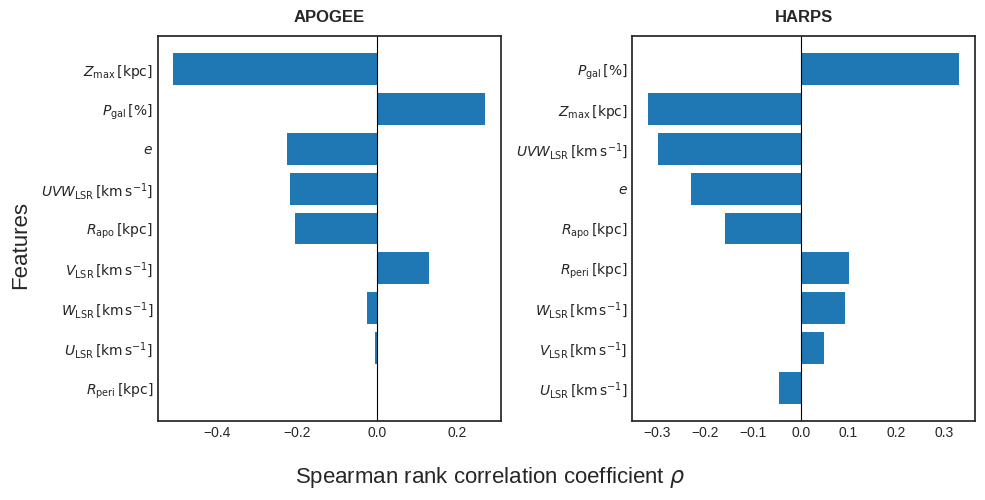

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=False)

datasets = {
    "APOGEE": corr_apogee,
    "HARPS": corr_harps,
    #"Combined": corr_full
}

axes = axes.flatten()

for ax, (name, corr) in zip(axes, datasets.items()):
    
    values = corr.values
    labels = [PRETTY_LABELS.get(f, f) for f in corr.index]
    
    ax.barh(labels, values)
    ax.set_title(name, fontsize=12)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()

# Global axis labels
fig.supxlabel(r"Spearman rank correlation coefficient $\rho$", fontsize=16)
fig.supylabel("Features", fontsize=16)

plt.tight_layout()
plt.savefig('./figures/correlations.png', dpi=300)
plt.show()

pandas-profiling (now renamed to ydata-profiling)
✅ What it gives:
Target correlation heatmaps

Distribution plots of features

Missing value analysis

Duplicates detection

Interaction matrices

Report export (HTML, JSON)

In [19]:
from ydata_profiling import ProfileReport
#profile = ProfileReport(X_harps.assign(fe_h=y_harps), title="EDA Report", explorative=True)
#profile.to_file("eda_report.html")  # Opens in your browser


In [20]:
import sweetviz as sv

#report = sv.analyze([harps, "Train"], target_feat="fe_h")
#report.show_html("sweetviz_report.html")


In [21]:
#sv.compare([X_combined_train.assign(fe_h=y_combined_train), "Train"], [harps, "Test"]).show_html("compare.html")


In [22]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np
import pandas as pd

def select_features_by_mi_and_correlation(X, y, corr_thresh=0.9, top_n=None, verbose=True):
    # 1. Compute mutual information
    mi = mutual_info_regression(X, y)
    mi_df = pd.DataFrame({'Feature': X.columns, 'MI': mi}).sort_values(by='MI', ascending=False)

    selected = []
    removed = []
    remaining = list(mi_df['Feature'])

    while remaining:
        # Pick the highest MI feature
        best = remaining.pop(0)
        selected.append(best)

        if verbose:
            print(f"Selected: {best} (MI={mi_df.set_index('Feature').loc[best, 'MI']:.4f})")

        # Remove features highly correlated with 'best'
        to_remove = []
        for feature in remaining:
            corr = np.corrcoef(X[best], X[feature])[0, 1]
            if abs(corr) > corr_thresh:
                to_remove.append(feature)

        for f in to_remove:
            remaining.remove(f)
            removed.append(f)
            if verbose:
                print(f"  Removed due to high correlation with {best}: {f} (|corr|={abs(np.corrcoef(X[best], X[f])[0, 1]):.2f})")

        # Stop if top_n features are selected
        if top_n and len(selected) >= top_n:
            break

    return selected, removed



In [23]:
selected_features_full, removed_features_full = select_features_by_mi_and_correlation(X_full, y_full, corr_thresh=0.999)
print("Selected:", selected_features_full)

Selected: zmax (MI=0.1781)
Selected: rperi (MI=0.1237)
Selected: P_gal (MI=0.0877)
Selected: eccentricity (MI=0.0770)
Selected: rapo (MI=0.0757)
Selected: V_lsr (MI=0.0705)
Selected: W_lsr (MI=0.0616)
Selected: UVW_lsr (MI=0.0531)
Selected: U_lsr (MI=0.0019)
Selected: ['zmax', 'rperi', 'P_gal', 'eccentricity', 'rapo', 'V_lsr', 'W_lsr', 'UVW_lsr', 'U_lsr']


In [24]:
mi_apogee = make_mi_scores(X_apogee, y=y_apogee, plot=False)
mi_harps  = make_mi_scores(X_harps,  y=y_harps,  plot=False)


First 9 of 9 features:
zmax            0.178300
rperi           0.123057
P_gal           0.084761
eccentricity    0.076359
rapo            0.076017
V_lsr           0.071684
W_lsr           0.059486
UVW_lsr         0.053878
U_lsr           0.001152
Name: MI Scores, dtype: float64
First 9 of 9 features:
P_gal           0.167251
UVW_lsr         0.156053
zmax            0.145673
rperi           0.113827
eccentricity    0.102472
W_lsr           0.098432
V_lsr           0.069948
U_lsr           0.041135
rapo            0.012397
Name: MI Scores, dtype: float64


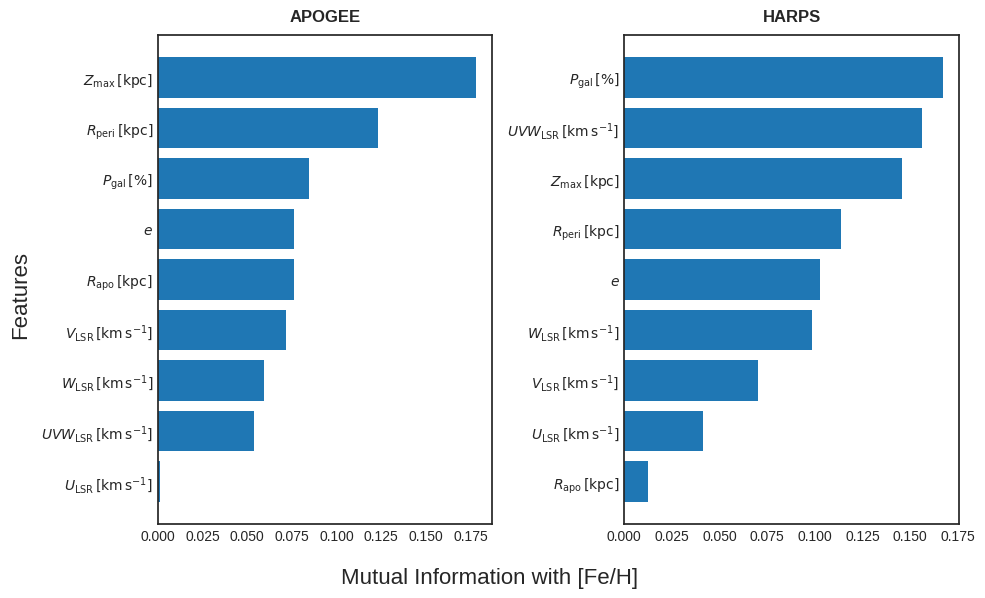

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=False)

datasets = {
    "APOGEE": mi_apogee,
    "HARPS": mi_harps
}

for ax, (name, mi) in zip(axes, datasets.items()):
    
    # Sort independently
    mi_sorted = mi.sort_values(ascending=False)
    
    labels = [PRETTY_LABELS.get(f, f) for f in mi_sorted.index]
    
    ax.barh(labels, mi_sorted.values)
    ax.set_title(name, fontsize=12)
    ax.invert_yaxis()

# Global axis labels
fig.supxlabel("Mutual Information with [Fe/H]", fontsize=16)
fig.supylabel("Features", fontsize=16)

plt.tight_layout()
plt.savefig('./figures/MI.png', dpi=300)
plt.show()

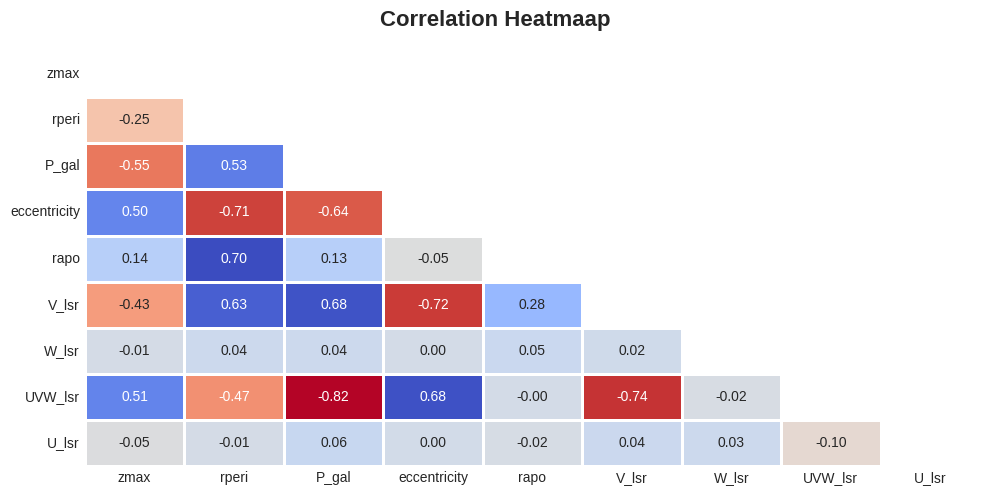

In [26]:
# Displays the correlation hitmap
corr_heatmap_plot(X_full[selected_features_full])

In [27]:
def compute_vif(X):
    X_const = add_constant(X.copy())
    
    vif_data = []
    for i in range(X_const.shape[1]):
        try:
            vif_value = variance_inflation_factor(X_const.values, i)
        except Exception:
            vif_value = np.inf
        
        vif_data.append((X_const.columns[i], vif_value))
    
    vif_df = pd.DataFrame(vif_data, columns=['Variable', 'VIF'])
    
    # Remove constant row
    vif_df = vif_df[vif_df['Variable'] != 'const']
    
    return vif_df

In [28]:
vif_apogee = compute_vif(X_apogee[selected_features_full])
vif_harps  = compute_vif(X_harps[selected_features_full])

vif_apogee_sorted = vif_apogee.sort_values("VIF", ascending=True)
vif_harps_sorted  = vif_harps.sort_values("VIF", ascending=True)

In [29]:
cap_value = 0

vif_apogee_plot = vif_apogee_sorted.copy()
vif_apogee_sorted["VIF_plot"] = vif_apogee_sorted["VIF"].replace(np.inf, cap_value)

vif_harps_plot = vif_harps_sorted.copy()
vif_harps_sorted["VIF_plot"] = vif_harps_sorted["VIF"].replace(np.inf, cap_value)

In [30]:
vif_apogee_sorted

,Variable,VIF,VIF_plot
7,W_lsr,1.006001,1.006001
9,U_lsr,1.024602,1.024602
1,zmax,1.626829,1.626829
3,P_gal,3.616845,3.616845
6,V_lsr,3.817697,3.817697
8,UVW_lsr,4.499807,4.499807
5,rapo,12.092053,12.092053
4,eccentricity,13.392207,13.392207
2,rperi,21.507648,21.507648


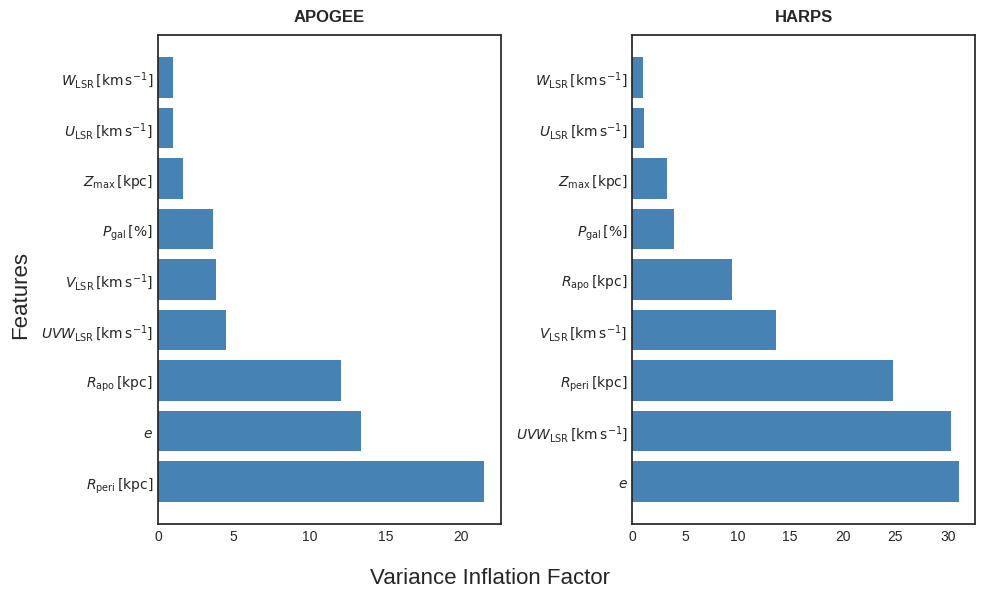

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=False)

datasets = {
    "APOGEE": vif_apogee_sorted,
    "HARPS": vif_harps_sorted
}


for ax, (name, vif_df) in zip(axes, datasets.items()):
    
    labels = [PRETTY_LABELS.get(f, f) for f in vif_df["Variable"]]
    
    
    ax.barh(labels, vif_df["VIF_plot"], color = 'steelblue')
    ax.set_title(name, fontsize=12)
    #ax.set_xscale("log")   # VERY important
    ax.invert_yaxis()
    # Annotate infinite VIFs
    for i, (vif, vif_plot) in enumerate(zip(vif_df["VIF"], vif_df["VIF_plot"])):
        if np.isinf(vif):
            ax.text(vif_plot+0.9, i, "  ∞", va="center", color = 'steelblue', fontsize=17, weight="bold")

fig.supxlabel("Variance Inflation Factor", fontsize=16)
fig.supylabel("Features", fontsize=16)

plt.tight_layout()
plt.savefig('./figures/VIF.png', dpi=300)
plt.show()

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
import numpy as np
import time

def model_test_CV_models(X, y, models, k=5, random_state=42):
    """
    Perform k-fold cross-validation for multiple models.
    Returns mean and std of RMSE, MAE, and R2.
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()

        rmse_scores = []
        mae_scores = []
        r2_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            rmse_scores.append(rmse)
            mae_scores.append(mae)
            r2_scores.append(r2)

        elapsed_time = time.time() - start_time

        results[name] = {
            'mean_rmse': np.mean(rmse_scores),
            'std_rmse': np.std(rmse_scores),
            'mean_mae': np.mean(mae_scores),
            'mean_r2': np.mean(r2_scores),
            'time_sec': elapsed_time
        }

        print(
            f"{name} → "
            f"RMSE: {results[name]['mean_rmse']:.3f} ± {results[name]['std_rmse']:.3f} | "
            f"MAE: {results[name]['mean_mae']:.3f} | "
            f"R²: {results[name]['mean_r2']:.3f} "
            f"({elapsed_time:.2f}s)\n"
        )

    return results

In [33]:
best_features = [x for x in selected_features_full if x not in []]

In [34]:
apogee_final_for_feh = apogee[[*best_features,'fe_h']]
apogee_final_for_feh.to_csv('apogee_final_for_feh.csv', index=False)

galah_final_for_feh = galah[[*best_features,'fe_h']]
galah_final_for_feh.to_csv('galah_final_for_feh.csv', index=False)

harps_final_for_feh = harps[[*best_features,'fe_h']]
harps_final_for_feh.to_csv('harps_final_for_feh.csv', index=False)